# AutoCause quickstart

One call runs the audit, preprocessing, discovery, consensus, evidence checks, figures, and provenance. AutoCause wraps established methods and records every analysis choice it makes.

Run the example, then supply your own time series. The [walkthrough](walkthrough.ipynb) covers configuration and interpretation in detail. Execution success and evidence grades do not establish causal truth.

## Setup

Use **Python 3.13**. With both repositories cloned as siblings, install from the AutoCause root:

```bash
python -m pip install -e . -e "../causal-audit[viz]" ipykernel
python -m ipykernel install --user --name autocause --display-name "Python (autocause)"
```

Select **Python (autocause)**. The version and import path printed below show which code is running, and this example needs the companion audit package.

Your data needs numeric columns and a chronological, unique `DatetimeIndex`. Set `sampling_days` to the real observation spacing, resolve duplicate timestamps, and document how gaps were handled.

The example has 600 daily observations, Gaussian innovations, and four known lag 1 links. Known edges are only used for scoring; discovery does not need them.

In [1]:
import json
import contextlib
import logging
from importlib.metadata import version
from pathlib import Path

# Relative output directory so the notebook is portable.
EXAMPLES_DIR = Path("examples") if Path("examples").is_dir() else Path(".")

# File-only backend: the pipeline's own figures are written to disk rather than
# embedded here. The plots below are saved and shown explicitly.
import matplotlib

matplotlib.use("Agg")
import matplotlib.pyplot as plt
from IPython.display import Image, display

import numpy as np
import pandas as pd
import autocause
from causal_audit import RiskAwareGatekeeper
from autocause.core.run_workflow import run_causal_discovery_workflow

print("AutoCause distribution:", version("autocause"))
print("Causal-Audit distribution:", version("causal-audit"))

output_dir = EXAMPLES_DIR / "quickstart_output"
output_dir.mkdir(parents=True, exist_ok=True)

rng = np.random.default_rng(0)
n = 600
x = np.zeros((n, 5))
# Cross-variable lag-1 structure: X0 -> X1, X1 -> X2, X0 -> X3, X3 -> X4.
# X0 also has an autoregressive self-link, excluded from this evaluation.
for t in range(1, n):
    x[t, 0] = 0.5 * x[t - 1, 0] + rng.normal(0, 1)
    x[t, 1] = 0.6 * x[t - 1, 0] + rng.normal(0, 1)
    x[t, 2] = 0.6 * x[t - 1, 1] + rng.normal(0, 1)
    x[t, 3] = 0.5 * x[t - 1, 0] + rng.normal(0, 1)
    x[t, 4] = 0.6 * x[t - 1, 3] + rng.normal(0, 1)

cols = ["X0", "X1", "X2", "X3", "X4"]
index = pd.date_range("2020-01-01", periods=n, freq="D")
df = pd.DataFrame(x, columns=cols, index=index)

true_edges = {("X0", "X1"), ("X1", "X2"), ("X0", "X3"), ("X3", "X4")}
print(f"Data: {df.shape[0]} rows, {df.shape[1]} variables")
print(f"Cross-variable ground-truth edges: {sorted(true_edges)}")


def show_fig(fig, name):
    """Save a figure to the output directory and show it inline."""
    path = output_dir / name
    fig.savefig(path, dpi=120, bbox_inches="tight")
    plt.close(fig)
    display(Image(filename=str(path)))

AutoCause distribution: 0.2.0
Causal-Audit distribution: 0.3.1
Data: 600 rows, 5 variables
Cross-variable ground-truth edges: [('X0', 'X1'), ('X0', 'X3'), ('X1', 'X2'), ('X3', 'X4')]


In [2]:
@contextlib.contextmanager
def notebook_log(path):
    """Optional notebook utility: retain verbose output without filling the page."""
    root_logger = logging.getLogger()
    previous_handlers = root_logger.handlers[:]
    previous_disable = root_logger.manager.disable
    try:
        with path.open("w") as log, contextlib.redirect_stdout(log), contextlib.redirect_stderr(log):
            root_logger.handlers = [logging.StreamHandler(log)]
            logging.disable(logging.NOTSET)
            yield
    finally:
        root_logger.handlers = previous_handlers
        logging.disable(previous_disable)


## Run the complete workflow

Turn on audit and consensus explicitly; the other stages are on by default. The packaged methods are Granger, transfer entropy, and PCMCI+. The audit fills in the fields you left unset, without replacing the method list.

`notebook_log` only redirects output to a file. Remove its `with` block to call the workflow directly. Read the warnings even when `success=True`: an audit abstention does not stop discovery.

In [3]:
easy_dir = output_dir / "easy_run"
easy_dir.mkdir(parents=True, exist_ok=True)
easy_log = easy_dir / "notebook_run.log"

# Output redirection is optional notebook presentation, not a workflow setting.
with notebook_log(easy_log):
    easy_result = run_causal_discovery_workflow(
        data_df=df,
        output_dir=easy_dir,
        sampling_days=1,
        enable_causal_audit=True,
        apply_audit_recommendation=True,
        enable_consensus=True,
    )

print(f"Workflow finished: success={easy_result['success']}")
print("Review verbose output:", easy_log)
print("Review workflow warnings:", easy_dir / "experiment.log")

Workflow finished: success=True
Review verbose output: quickstart_output/easy_run/notebook_run.log
Review workflow warnings: quickstart_output/easy_run/experiment.log


Audit decision: RECOMMEND
Proposed method: PCMCI+


,source,target,lag_steps,vote_count,tier
0,X3,X4,1,3,1
1,X1,X2,1,3,1
2,X0,X1,1,3,1
3,X0,X3,1,3,1
4,X2,X3,2,1,3


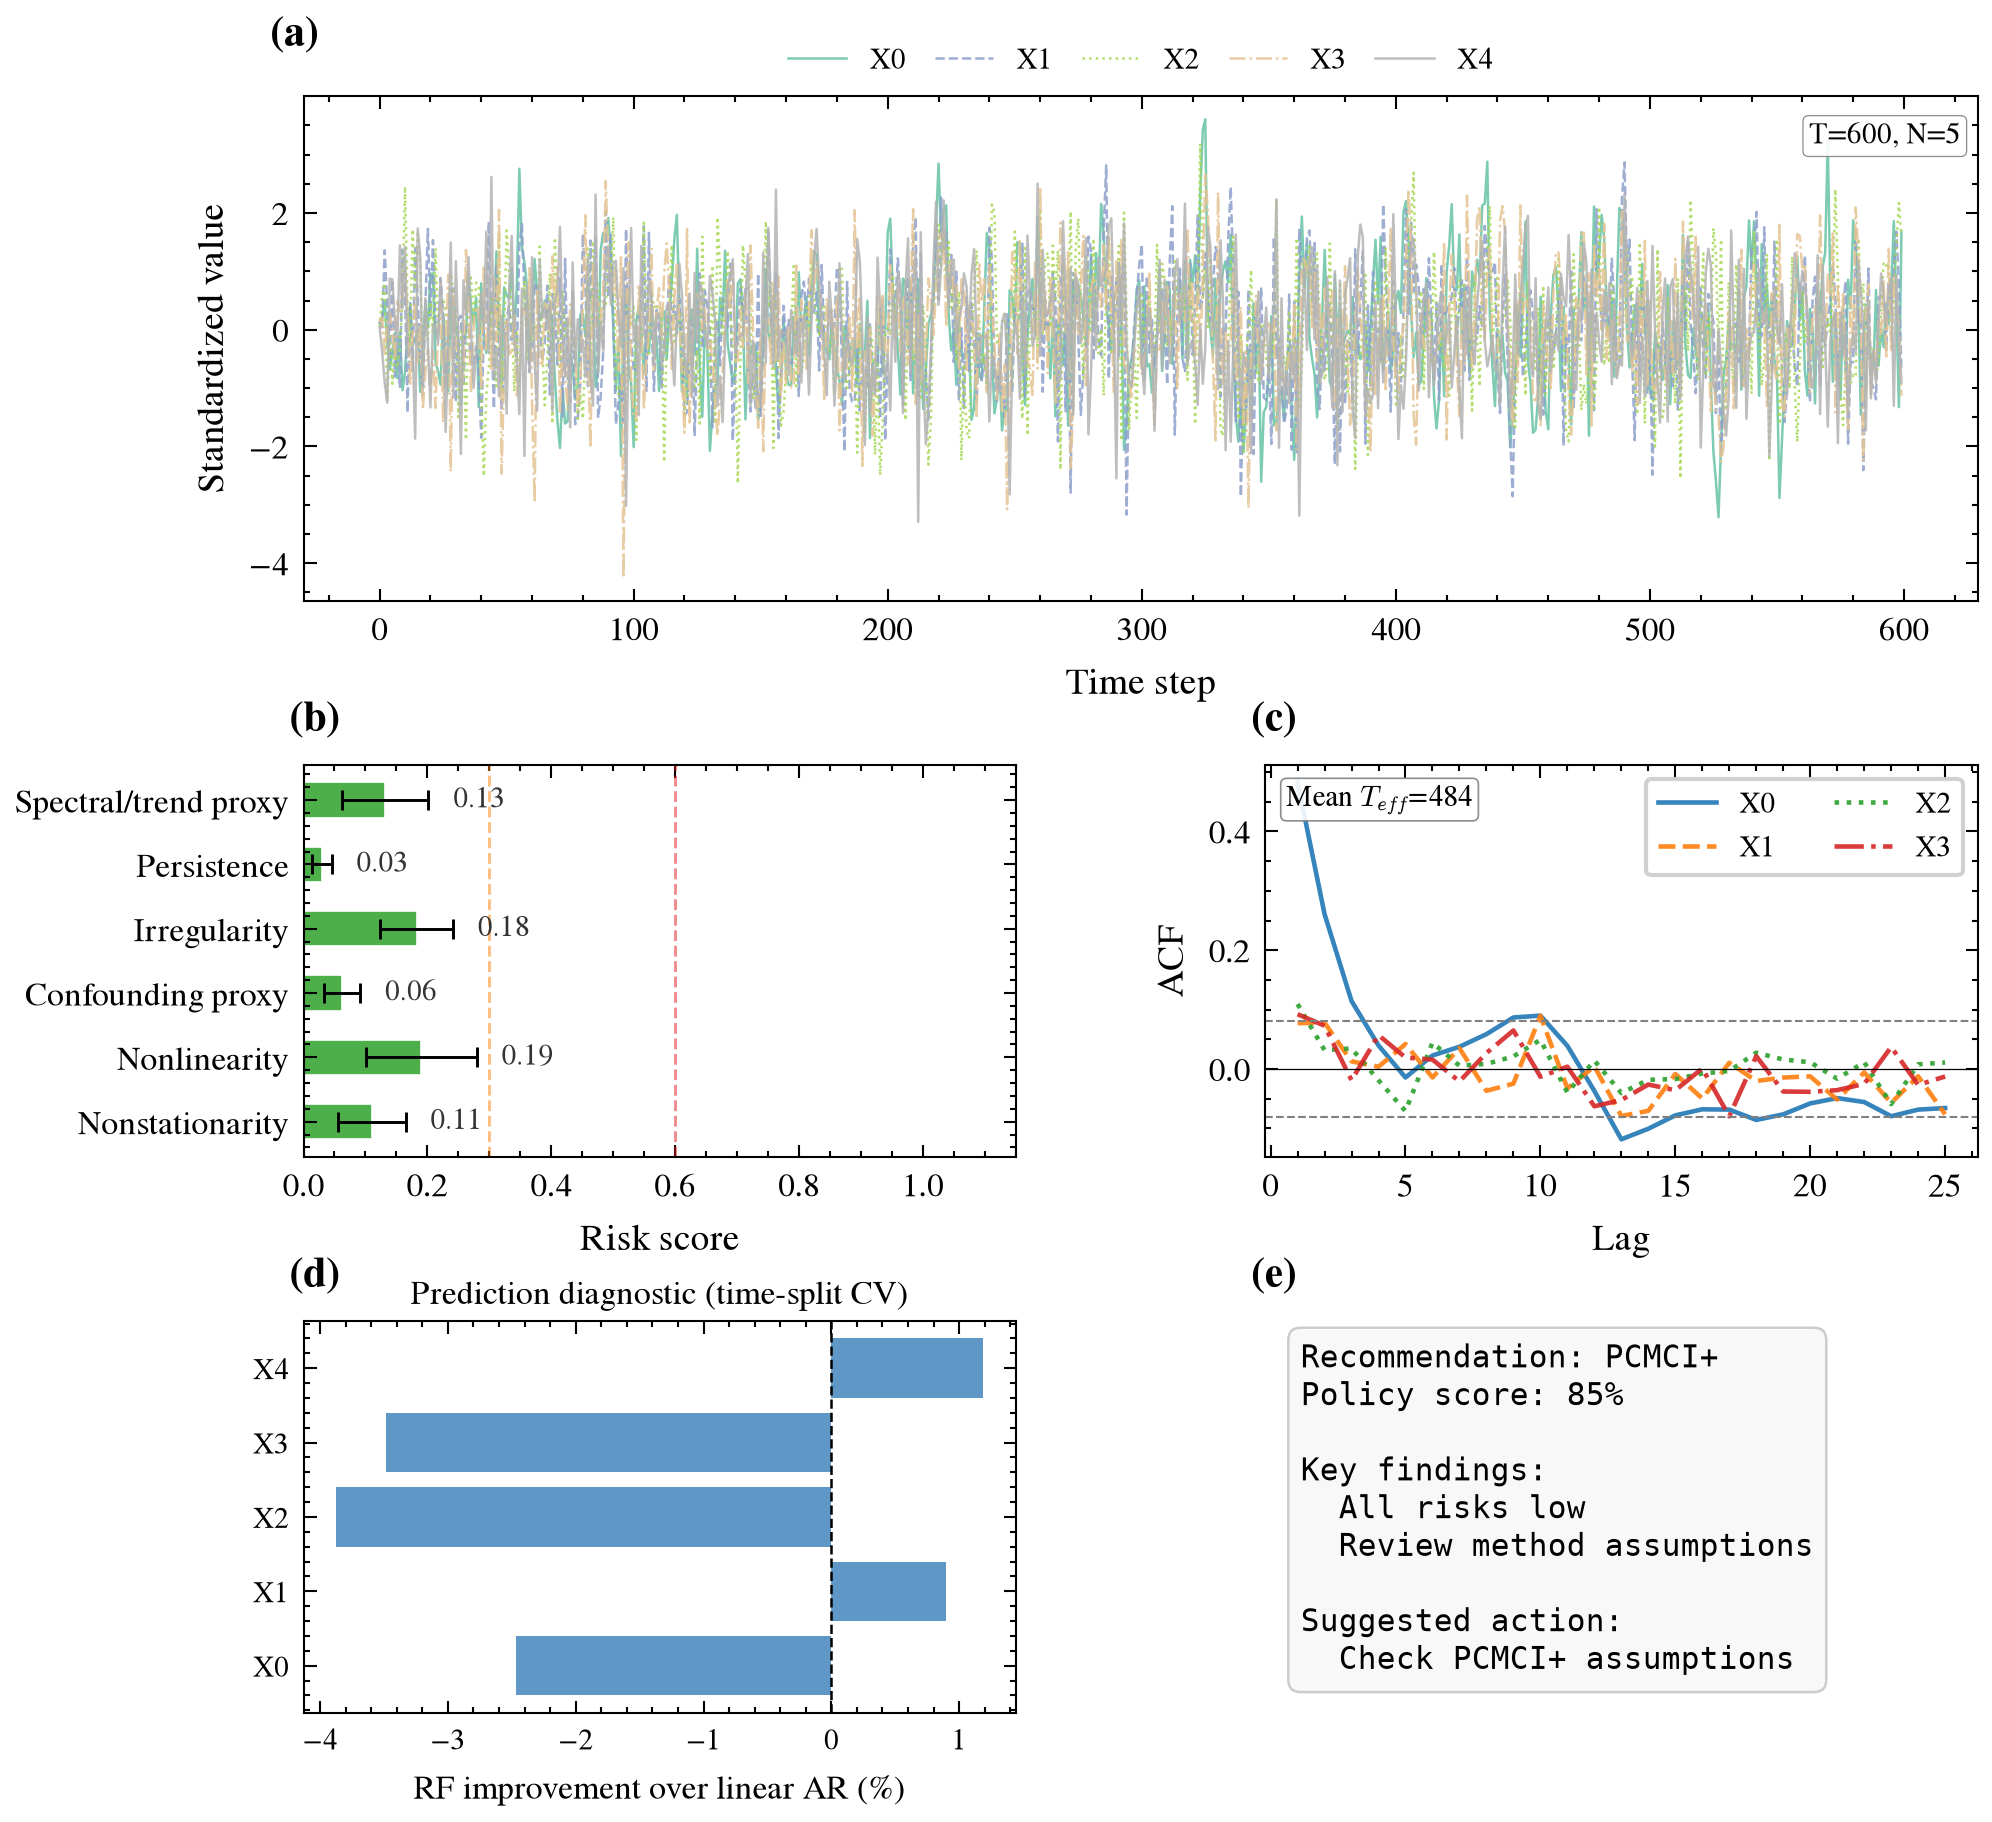

In [4]:
easy_policy = json.loads((easy_dir / "causal_audit/recommendation_policy.json").read_text())
print("Audit decision:", easy_policy["decision"].upper())
print("Proposed method:", easy_policy.get("recommended_method") or "none — investigate the audit")
easy_tiers_path = easy_dir / "consensus/5-tiers/consensus_with_tiers.csv"
if easy_tiers_path.exists():
    easy_tiers = pd.read_csv(easy_tiers_path)
    display(easy_tiers[["source", "target", "lag_steps", "vote_count", "tier"]])
else:
    print("No graded consensus file; inspect method outputs and experiment.log.")

display(Image(filename=str(easy_dir / "causal_audit/figures/prediscovery_summary.png"), width=950))

The audit summary above explains the recommendation. The PCMCI matrix below shows the reported pair values. This run uses BH adjustment in Tigramite; blank cells have no reported value. Stars mark values below 0.05 and say nothing about causal orientation or lag.

Read the lags and votes in the consensus table. Tiers are internal evidence grades, and the [walkthrough](walkthrough.ipynb) explains the checks behind them.

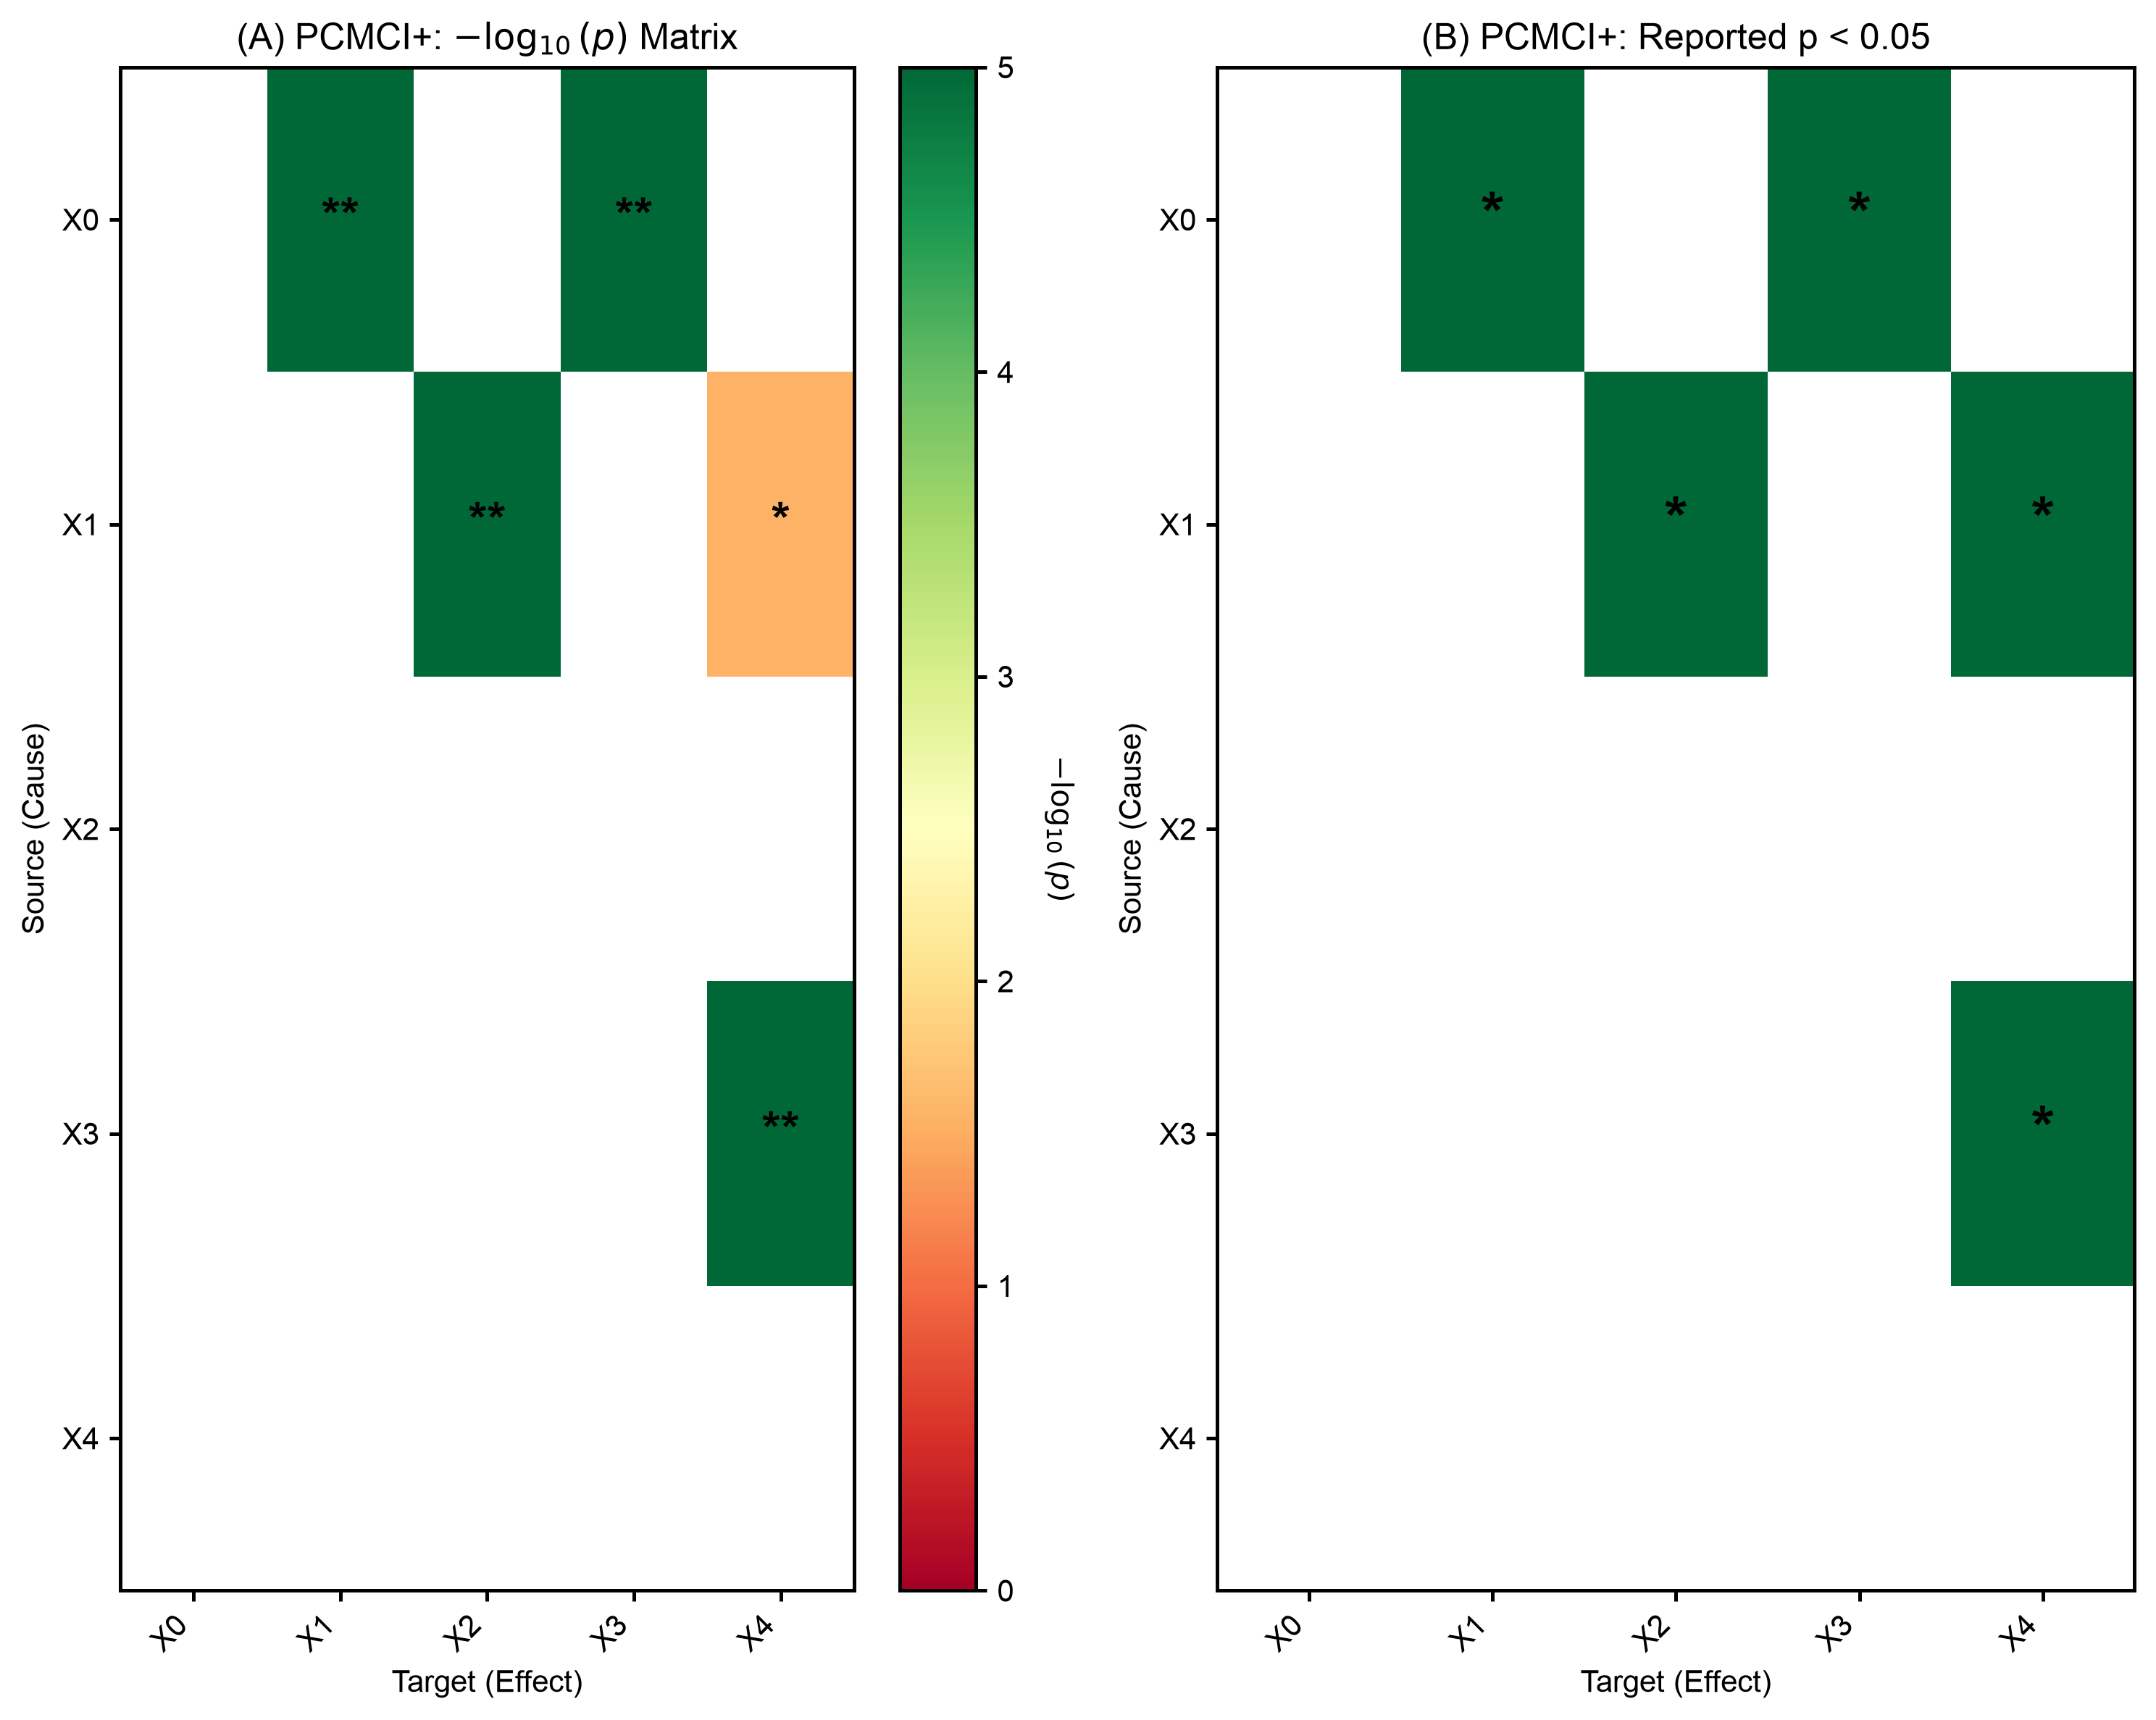

In [5]:
easy_method_figure = easy_dir / "figures/per_method/pcmci_ci_matrix.png"
if easy_method_figure.exists():
    display(Image(filename=str(easy_method_figure), width=950))
else:
    print("PCMCI figure unavailable; inspect experiment.log and method/pcmci/1-raw/.")

## Use your own data

Replace `df`, match the sampling interval, and choose a fresh output directory. No known graph is needed.

Read the scorecard, the preprocessing and lag records, the method CSVs, and `tier_report.txt`. Investigate warnings and failed checks, and keep the original input, settings, and environment.

The [walkthrough](walkthrough.ipynb) covers configuration, preprocessing, baselines, and evidence grades. Restart the kernel after changing package code.